# Affine registration with a sign-only template

Same affine setting as `affine_registration.ipynb`, with the access restriction from `rotation_registration_sign_template.ipynb`: the optimizer sees only the **sign** of the original image as a 0/1 field. The warped observation still has full grayscale values plus noise.

A random 0/1 control is registered to the same observation. If that arm recovers high bit accuracy or locks onto the true transform, the procedure can invent correspondences.

Results go to `results/affine_registration_sign_template/`.


## 1. Configuration


In [1]:
from pathlib import Path
import json
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import ndimage
from scipy.optimize import differential_evolution, minimize

SEED = 42
IMAGE_SIZE = 64
NOISE_LEVELS = [0.0, 0.1, 0.25, 0.5, 1.0]
N_TRIALS = 100
WARP_ORDER = 1
VALID_RADIUS_FRAC = 0.32

ANGLE_RANGE = (-15.0, 15.0)
SCALE_RANGE = (0.9, 1.1)
SHEAR_RANGE = (-0.1, 0.1)
TRANSLATION_RANGE = (-3.0, 3.0)

COARSE_ANGLE_STEP = 2.0
COARSE_TRANSLATION_STEP = 2.0

PARAM_NAMES = ["angle_deg", "scale_x", "scale_y", "shear", "tx", "ty"]
BOUNDS = [ANGLE_RANGE, SCALE_RANGE, SCALE_RANGE, SHEAR_RANGE, TRANSLATION_RANGE, TRANSLATION_RANGE]
LB = np.array([b[0] for b in BOUNDS], dtype=float)
UB = np.array([b[1] for b in BOUNDS], dtype=float)
SCIPY_BOUNDS = list(zip(LB, UB))

OUTPUT_DIR = Path("results/affine_registration_sign_template")
FIGURES_DIR = OUTPUT_DIR / "figures"

plt.rcParams.update({
    "figure.dpi": 120,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "font.size": 11,
})
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
print(f"image {IMAGE_SIZE}x{IMAGE_SIZE}, trials/noise={N_TRIALS}")
print(f"output -> {OUTPUT_DIR.resolve()}")


image 64x64, trials/noise=100
output -> C:\Users\samco\OneDrive\Desktop\gaussian_rotation\results\affine_registration_sign_template


## 2. Method

**Generation.** Continuous template \(I\) has i.i.d. standard normal pixels. A six-parameter affine
\((\theta, s_x, s_y, k, t_x, t_y)\) is drawn in the same ranges as `affine_registration.ipynb`. The observation is
\[
Y = W_{A,t}(I) + \sigma\varepsilon.
\]
The matched bit field is \(B = \mathbf{1}[I \ge 0]\) (exact zero counts as 1).

**Access.** The optimizer may use only \(B\) and \(Y\). It never sees the grayscale values of \(I\).

**Objective.** Let \(B_\pm = 2B - 1 \in \{\pm 1\}\). For a candidate affine, warp \(B_\pm\) into the observation frame with bilinear interpolation and maximize
\[
\mathrm{corr}\bigl(W_{A,t}(B_\pm),\, Y\bigr)
\]
on a fixed circular valid mask. That uses full grayscale \(Y\) and only signs of the template.

**Evaluation.** Inverse-warp \(Y\) back to the template frame and compare to \(B_\pm\):
- bit accuracy: fraction of sites with \(\mathrm{sign}(\tilde Y) = B_\pm\)
- bit MSE between \(B_\pm\) and \(\mathrm{sign}(\tilde Y)\)
- continuous correlation / MSE between \(B_\pm\) and \(\tilde Y\)

**Optimization.** Staged coarse search over angle and translation (unit scale, zero shear), then L-BFGS-B on all six parameters. Differential evolution runs only if the refine fails to improve on the identity map.

**Random control.** An independent sign field is registered to the same \(Y\) with the same optimizer.


In [2]:
def params_to_matrix(params: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    angle, sx, sy, shear, tx, ty = np.asarray(params, dtype=float)
    theta = np.deg2rad(angle)
    cos_t, sin_t = np.cos(theta), np.sin(theta)
    rotation = np.array([[cos_t, -sin_t], [sin_t, cos_t]], dtype=float)
    linear = np.array([[sx, sx * shear], [0.0, sy]], dtype=float)
    return rotation @ linear, np.array([tx, ty], dtype=float)


def image_center(shape: tuple[int, int]) -> np.ndarray:
    return np.array(shape, dtype=float) / 2.0 - 0.5


def warp_affine(image: np.ndarray, matrix: np.ndarray, translation: np.ndarray) -> np.ndarray:
    center = image_center(image.shape)
    inverse = np.linalg.inv(matrix)
    affine = np.zeros((2, 3), dtype=float)
    affine[:, :2] = inverse
    affine[:, 2] = -inverse @ (center + translation) + center
    return ndimage.affine_transform(
        image,
        affine,
        order=WARP_ORDER,
        mode="constant",
        cval=0.0,
        prefilter=True,
    )


def invert_params(params: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    matrix, translation = params_to_matrix(params)
    inverse = np.linalg.inv(matrix)
    return inverse, -inverse @ translation


def circular_valid_mask(shape: tuple[int, int], radius_frac: float = VALID_RADIUS_FRAC) -> np.ndarray:
    height, width = shape
    center_y, center_x = image_center(shape)
    rows, cols = np.mgrid[0:height, 0:width]
    radius = radius_frac * float(min(height, width))
    return (rows - center_y) ** 2 + (cols - center_x) ** 2 <= radius ** 2


def bits_from_continuous(image: np.ndarray) -> np.ndarray:
    return (np.asarray(image) >= 0).astype(np.float64)


def bits_to_pm(bits01: np.ndarray) -> np.ndarray:
    return 2.0 * bits01 - 1.0


def sign_pm(image: np.ndarray) -> np.ndarray:
    return np.where(np.asarray(image) >= 0, 1.0, -1.0)


def sample_params(rng: np.random.Generator) -> np.ndarray:
    for _ in range(1000):
        params = np.array(
            [
                rng.uniform(*ANGLE_RANGE),
                rng.uniform(*SCALE_RANGE),
                rng.uniform(*SCALE_RANGE),
                rng.uniform(*SHEAR_RANGE),
                rng.uniform(*TRANSLATION_RANGE),
                rng.uniform(*TRANSLATION_RANGE),
            ],
            dtype=float,
        )
        matrix, _ = params_to_matrix(params)
        if abs(np.linalg.det(matrix)) >= 0.7:
            return params
    raise RuntimeError("failed to sample a well-conditioned affine transform")


def masked_corr(a: np.ndarray, b: np.ndarray, mask: np.ndarray) -> float:
    left = np.asarray(a, dtype=float)[mask]
    right = np.asarray(b, dtype=float)[mask]
    if left.size < 2 or np.std(left) < 1e-12 or np.std(right) < 1e-12:
        return 0.0
    return float(np.corrcoef(left, right)[0, 1])


def score_alignment(bits01: np.ndarray, observation: np.ndarray, params: np.ndarray, mask: np.ndarray) -> dict:
    bits_pm = bits_to_pm(bits01)
    forward = warp_affine(bits_pm, *params_to_matrix(params))
    inverse_matrix, inverse_translation = invert_params(params)
    back = warp_affine(observation, inverse_matrix, inverse_translation)
    signed_back = sign_pm(back)
    bits_m = bits_pm[mask]
    back_m = back[mask]
    signed_m = signed_back[mask]
    return {
        "forward_correlation": masked_corr(forward, observation, mask),
        "bit_accuracy": float(np.mean(signed_m == bits_m)),
        "bit_mse": float(np.mean((bits_m - signed_m) ** 2)),
        "continuous_correlation": masked_corr(bits_pm, back, mask),
        "continuous_mse": float(np.mean((bits_m - back_m) ** 2)),
    }


def matrix_error(params_a: np.ndarray, params_b: np.ndarray) -> float:
    matrix_a, translation_a = params_to_matrix(params_a)
    matrix_b, translation_b = params_to_matrix(params_b)
    linear = np.linalg.norm(matrix_a - matrix_b, ord="fro")
    shift = np.linalg.norm(translation_a - translation_b)
    return float(np.sqrt(linear**2 + shift**2))


VALID_MASK = circular_valid_mask((IMAGE_SIZE, IMAGE_SIZE))
print(f"valid pixels: {int(VALID_MASK.sum())} / {IMAGE_SIZE * IMAGE_SIZE} ({100 * VALID_MASK.mean():.1f}%)")


valid pixels: 1304 / 4096 (31.8%)


In [3]:
def forward_correlation(bits_pm: np.ndarray, observation: np.ndarray, params: np.ndarray, mask: np.ndarray) -> float:
    warped = warp_affine(bits_pm, *params_to_matrix(params))
    return masked_corr(warped, observation, mask)


def coarse_initialize(bits_pm: np.ndarray, observation: np.ndarray, mask: np.ndarray) -> np.ndarray:
    identity = np.array([0.0, 1.0, 1.0, 0.0, 0.0, 0.0], dtype=float)
    best_params = identity.copy()
    best_corr = forward_correlation(bits_pm, observation, best_params, mask)

    for angle in np.arange(ANGLE_RANGE[0], ANGLE_RANGE[1] + 0.5 * COARSE_ANGLE_STEP, COARSE_ANGLE_STEP):
        params = np.array([angle, 1.0, 1.0, 0.0, 0.0, 0.0], dtype=float)
        corr = forward_correlation(bits_pm, observation, params, mask)
        if corr > best_corr:
            best_corr = corr
            best_params = params

    for tx in np.arange(TRANSLATION_RANGE[0], TRANSLATION_RANGE[1] + 0.5 * COARSE_TRANSLATION_STEP, COARSE_TRANSLATION_STEP):
        for ty in np.arange(TRANSLATION_RANGE[0], TRANSLATION_RANGE[1] + 0.5 * COARSE_TRANSLATION_STEP, COARSE_TRANSLATION_STEP):
            params = np.array([0.0, 1.0, 1.0, 0.0, tx, ty], dtype=float)
            corr = forward_correlation(bits_pm, observation, params, mask)
            if corr > best_corr:
                best_corr = corr
                best_params = params

    angle0, _, _, _, tx0, ty0 = best_params
    for angle in np.unique(np.clip([angle0 - COARSE_ANGLE_STEP, angle0, angle0 + COARSE_ANGLE_STEP], *ANGLE_RANGE)):
        for tx in np.unique(np.clip([tx0 - COARSE_TRANSLATION_STEP, tx0, tx0 + COARSE_TRANSLATION_STEP], *TRANSLATION_RANGE)):
            for ty in np.unique(np.clip([ty0 - COARSE_TRANSLATION_STEP, ty0, ty0 + COARSE_TRANSLATION_STEP], *TRANSLATION_RANGE)):
                params = np.array([angle, 1.0, 1.0, 0.0, tx, ty], dtype=float)
                corr = forward_correlation(bits_pm, observation, params, mask)
                if corr > best_corr:
                    best_corr = corr
                    best_params = params
    return best_params


def register_sign_affine(bits01: np.ndarray, observation: np.ndarray, mask: np.ndarray) -> dict:
    started = time.perf_counter()
    bits_pm = bits_to_pm(bits01)
    init = coarse_initialize(bits_pm, observation, mask)
    identity = np.array([0.0, 1.0, 1.0, 0.0, 0.0, 0.0], dtype=float)
    identity_corr = forward_correlation(bits_pm, observation, identity, mask)

    def objective(params: np.ndarray) -> float:
        return -forward_correlation(bits_pm, observation, params, mask)

    refined = minimize(
        objective,
        init,
        method="L-BFGS-B",
        bounds=SCIPY_BOUNDS,
        options={"ftol": 1e-10, "gtol": 1e-8, "maxiter": 400},
    )
    estimate = np.asarray(refined.x, dtype=float)
    corr = forward_correlation(bits_pm, observation, estimate, mask)
    method = "coarse+L-BFGS-B"

    if corr <= identity_corr + 1e-6:
        de = differential_evolution(
            objective,
            BOUNDS,
            polish=True,
            tol=1e-5,
            popsize=5,
            seed=SEED,
        )
        refined = minimize(
            objective,
            de.x,
            method="L-BFGS-B",
            bounds=SCIPY_BOUNDS,
            options={"ftol": 1e-10, "gtol": 1e-8, "maxiter": 200},
        )
        estimate = np.asarray(refined.x, dtype=float)
        corr = forward_correlation(bits_pm, observation, estimate, mask)
        method = "differential_evolution+L-BFGS-B"

    metrics = score_alignment(bits01, observation, estimate, mask)
    return {
        "estimated_params": estimate,
        "init_params": init,
        "forward_correlation": corr,
        "identity_correlation": identity_corr,
        "method": method,
        "runtime_s": time.perf_counter() - started,
        **metrics,
    }


_warmup_rng = np.random.default_rng(0)
_template = _warmup_rng.standard_normal((IMAGE_SIZE, IMAGE_SIZE))
_bits = bits_from_continuous(_template)
_true = sample_params(_warmup_rng)
_obs = warp_affine(_template, *params_to_matrix(_true))
_fit = register_sign_affine(_bits, _obs, VALID_MASK)
print(
    f"warm-up matched: method={_fit['method']}, forward_corr={_fit['forward_correlation']:.3f}, "
    f"bit_acc={_fit['bit_accuracy']:.3f}, matrix_err={matrix_error(_fit['estimated_params'], _true):.3f}, "
    f"runtime={_fit['runtime_s']:.3f}s"
)
_rand = register_sign_affine(bits_from_continuous(_warmup_rng.standard_normal((IMAGE_SIZE, IMAGE_SIZE))), _obs, VALID_MASK)
print(
    f"warm-up random:  method={_rand['method']}, forward_corr={_rand['forward_correlation']:.3f}, "
    f"bit_acc={_rand['bit_accuracy']:.3f}, matrix_err={matrix_error(_rand['estimated_params'], _true):.3f}"
)


warm-up matched: method=coarse+L-BFGS-B, forward_corr=0.816, bit_acc=0.805, matrix_err=0.017, runtime=0.097s


warm-up random:  method=coarse+L-BFGS-B, forward_corr=0.088, bit_acc=0.522, matrix_err=3.776


## 3. Example trial

Matched bits, random bits, and the noisy observation. Parameter recovery and bit scores are printed for both arms.


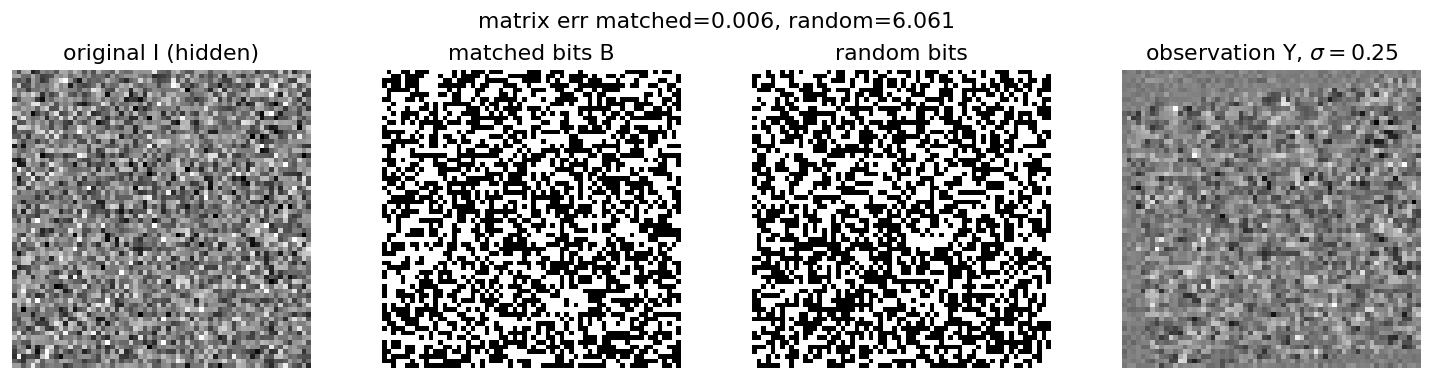

parameter   true  matched_est  random_est  matched_abs_err  random_abs_err
angle_deg 6.0420       5.9641     -1.9974           0.0780          8.0394
  scale_x 0.9122       0.9142      1.0230           0.0021          0.1109
  scale_y 1.0080       1.0079      0.9829           0.0001          0.0251
    shear 0.0095       0.0093     -0.0095           0.0002          0.0190
       tx 1.5405       1.5452      3.0000           0.0047          1.4595
       ty 2.8959       2.8972     -2.9824           0.0013          5.8783
matched bit_acc=0.7738, random bit_acc=0.5207, random at true=0.4893


In [4]:
example_rng = np.random.default_rng(SEED)
example_template = example_rng.standard_normal((IMAGE_SIZE, IMAGE_SIZE))
example_matched_bits = bits_from_continuous(example_template)
example_random_bits = bits_from_continuous(example_rng.standard_normal((IMAGE_SIZE, IMAGE_SIZE)))
example_true = sample_params(example_rng)
example_noise = 0.25
example_clean = warp_affine(example_template, *params_to_matrix(example_true))
example_obs = example_clean + example_noise * example_rng.standard_normal((IMAGE_SIZE, IMAGE_SIZE))
example_matched = register_sign_affine(example_matched_bits, example_obs, VALID_MASK)
example_random = register_sign_affine(example_random_bits, example_obs, VALID_MASK)
example_random_at_true = score_alignment(example_random_bits, example_obs, example_true, VALID_MASK)

vmax = float(np.percentile(np.abs(example_template), 99))
fig, axes = plt.subplots(1, 4, figsize=(12.5, 3.2))
axes[0].imshow(example_template, cmap="gray", vmin=-vmax, vmax=vmax, interpolation="nearest")
axes[0].set_title("original I (hidden)")
axes[1].imshow(example_matched_bits, cmap="gray", vmin=0, vmax=1, interpolation="nearest")
axes[1].set_title("matched bits B")
axes[2].imshow(example_random_bits, cmap="gray", vmin=0, vmax=1, interpolation="nearest")
axes[2].set_title("random bits")
axes[3].imshow(example_obs, cmap="gray", vmin=-vmax, vmax=vmax, interpolation="nearest")
axes[3].set_title(rf"observation Y, $\sigma={example_noise}$")
for ax in axes:
    ax.axis("off")
fig.suptitle(
    f"matrix err matched={matrix_error(example_matched['estimated_params'], example_true):.3f}, "
    f"random={matrix_error(example_random['estimated_params'], example_true):.3f}"
)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "example_images.png", bbox_inches="tight")
plt.show()

compare = pd.DataFrame({
    "parameter": PARAM_NAMES,
    "true": example_true,
    "matched_est": example_matched["estimated_params"],
    "random_est": example_random["estimated_params"],
    "matched_abs_err": np.abs(example_matched["estimated_params"] - example_true),
    "random_abs_err": np.abs(example_random["estimated_params"] - example_true),
})
print(compare.round(4).to_string(index=False))
print(
    f"matched bit_acc={example_matched['bit_accuracy']:.4f}, "
    f"random bit_acc={example_random['bit_accuracy']:.4f}, "
    f"random at true={example_random_at_true['bit_accuracy']:.4f}"
)


## 4. Full experiment

Matched and random arms share the same continuous image, true affine, and noisy observation within a trial. Across noise levels only the noise draw changes.


In [5]:
def run_experiment(n_trials: int, noise_levels: list[float], seed: int) -> pd.DataFrame:
    rows = []
    started = time.perf_counter()
    total = n_trials * len(noise_levels)
    done = 0
    for trial in range(n_trials):
        trial_rng = np.random.default_rng(seed + 10_000 * trial + 31)
        template = trial_rng.standard_normal((IMAGE_SIZE, IMAGE_SIZE))
        matched_bits = bits_from_continuous(template)
        random_bits = bits_from_continuous(trial_rng.standard_normal((IMAGE_SIZE, IMAGE_SIZE)))
        true_params = sample_params(trial_rng)
        clean = warp_affine(template, *params_to_matrix(true_params))
        for noise_std in noise_levels:
            noise_rng = np.random.default_rng(seed + 10_000 * trial + int(1_000_000 * noise_std) + 41)
            observation = clean + noise_std * noise_rng.standard_normal((IMAGE_SIZE, IMAGE_SIZE))
            matched = register_sign_affine(matched_bits, observation, VALID_MASK)
            random = register_sign_affine(random_bits, observation, VALID_MASK)
            random_at_true = score_alignment(random_bits, observation, true_params, VALID_MASK)
            row = {
                "trial": trial,
                "noise_std": float(noise_std),
                "matched_method": matched["method"],
                "random_method": random["method"],
                "matched_runtime_s": matched["runtime_s"],
                "random_runtime_s": random["runtime_s"],
                "matched_matrix_error": matrix_error(matched["estimated_params"], true_params),
                "random_matrix_error": matrix_error(random["estimated_params"], true_params),
                "matched_bit_accuracy": matched["bit_accuracy"],
                "matched_bit_mse": matched["bit_mse"],
                "matched_forward_correlation": matched["forward_correlation"],
                "matched_continuous_correlation": matched["continuous_correlation"],
                "matched_continuous_mse": matched["continuous_mse"],
                "random_bit_accuracy": random["bit_accuracy"],
                "random_bit_mse": random["bit_mse"],
                "random_forward_correlation": random["forward_correlation"],
                "random_continuous_correlation": random["continuous_correlation"],
                "random_bit_accuracy_at_true": random_at_true["bit_accuracy"],
                "random_continuous_correlation_at_true": random_at_true["continuous_correlation"],
            }
            for name, truth, matched_hat, random_hat in zip(
                PARAM_NAMES,
                true_params,
                matched["estimated_params"],
                random["estimated_params"],
            ):
                row[f"true_{name}"] = float(truth)
                row[f"matched_est_{name}"] = float(matched_hat)
                row[f"random_est_{name}"] = float(random_hat)
                row[f"matched_abs_err_{name}"] = float(abs(matched_hat - truth))
                row[f"random_abs_err_{name}"] = float(abs(random_hat - truth))
            rows.append(row)
            done += 1
            if done == 1 or done == total or done % max(1, total // 10) == 0:
                elapsed = time.perf_counter() - started
                eta = (total - done) / (done / max(elapsed, 1e-9))
                print(
                    f"[{done}/{total}] trial={trial} sigma={noise_std:g} "
                    f"matched_bit={row['matched_bit_accuracy']:.3f} "
                    f"random_bit={row['random_bit_accuracy']:.3f} "
                    f"matched_Merr={row['matched_matrix_error']:.3f} "
                    f"elapsed={elapsed:.1f}s eta={eta:.1f}s",
                    flush=True,
                )
    return pd.DataFrame(rows)


results = run_experiment(N_TRIALS, NOISE_LEVELS, SEED)
results.to_csv(OUTPUT_DIR / "trial_results.csv", index=False)
print(f"wrote {OUTPUT_DIR / 'trial_results.csv'} ({len(results)} rows)")


[1/500] trial=0 sigma=0 matched_bit=0.836 random_bit=0.534 matched_Merr=0.017 elapsed=0.3s eta=145.3s


[50/500] trial=9 sigma=1 matched_bit=0.683 random_bit=0.508 matched_Merr=0.051 elapsed=117.4s eta=1056.8s


[100/500] trial=19 sigma=1 matched_bit=0.668 random_bit=0.521 matched_Merr=0.019 elapsed=230.2s eta=920.8s


[150/500] trial=29 sigma=1 matched_bit=0.668 random_bit=0.552 matched_Merr=0.052 elapsed=250.2s eta=583.7s


[200/500] trial=39 sigma=1 matched_bit=0.554 random_bit=0.516 matched_Merr=2.637 elapsed=271.7s eta=407.5s


...

[350/500] trial=69 sigma=1 matched_bit=0.687 random_bit=0.539 matched_Merr=0.041 elapsed=402.5s eta=172.5s


[400/500] trial=79 sigma=1 matched_bit=0.679 random_bit=0.525 matched_Merr=0.029 elapsed=422.2s eta=105.5s


[450/500] trial=89 sigma=1 matched_bit=0.688 random_bit=0.521 matched_Merr=0.058 elapsed=443.2s eta=49.2s


[500/500] trial=99 sigma=1 matched_bit=0.671 random_bit=0.521 matched_Merr=0.117 elapsed=462.2s eta=0.0s


wrote results\affine_registration_sign_template\trial_results.csv (500 rows)


## 5. Summary: matched versus random control

Chance bit accuracy is \(1/2\). Parameter errors keep their native units (degrees, dimensionless scale/shear, pixels). Matrix error combines \(\|A-\hat A\|_F\) and \(\|t-\hat t\|_2\).


In [6]:
summary_rows = []
for noise_std, block in results.groupby("noise_std"):
    row = {
        "noise_std": float(noise_std),
        "n": int(len(block)),
        "matched_mean_matrix_error": float(block.matched_matrix_error.mean()),
        "matched_std_matrix_error": float(block.matched_matrix_error.std(ddof=1)),
        "random_mean_matrix_error": float(block.random_matrix_error.mean()),
        "matched_mean_bit_accuracy": float(block.matched_bit_accuracy.mean()),
        "random_mean_bit_accuracy": float(block.random_bit_accuracy.mean()),
        "random_bit_accuracy_at_true": float(block.random_bit_accuracy_at_true.mean()),
        "matched_mean_forward_corr": float(block.matched_forward_correlation.mean()),
        "random_mean_forward_corr": float(block.random_forward_correlation.mean()),
        "matched_mean_bit_mse": float(block.matched_bit_mse.mean()),
        "random_mean_bit_mse": float(block.random_bit_mse.mean()),
        "matched_mean_runtime_s": float(block.matched_runtime_s.mean()),
    }
    for name in PARAM_NAMES:
        row[f"matched_mae_{name}"] = float(block[f"matched_abs_err_{name}"].mean())
        row[f"random_mae_{name}"] = float(block[f"random_abs_err_{name}"].mean())
    summary_rows.append(row)
summary = pd.DataFrame(summary_rows).sort_values("noise_std").reset_index(drop=True)
summary.to_csv(OUTPUT_DIR / "summary_by_noise.csv", index=False)

show = summary[
    [
        "noise_std",
        "matched_mean_matrix_error",
        "random_mean_matrix_error",
        "matched_mean_bit_accuracy",
        "random_mean_bit_accuracy",
        "random_bit_accuracy_at_true",
        "matched_mae_angle_deg",
        "matched_mae_tx",
        "matched_mae_ty",
        "matched_mean_runtime_s",
    ]
]
print(show.round(4).to_string(index=False))
zero = summary.loc[np.isclose(summary.noise_std, 0.0)].iloc[0]
print(
    f"\nZero-noise matched: matrix err={zero.matched_mean_matrix_error:.4f}, "
    f"bit accuracy={zero.matched_mean_bit_accuracy:.4f}."
)
print(
    f"Zero-noise random: bit accuracy at estimate={zero.random_mean_bit_accuracy:.4f}, "
    f"at true transform={zero.random_bit_accuracy_at_true:.4f} (chance=0.5)."
)


 noise_std  matched_mean_matrix_error  random_mean_matrix_error  matched_mean_bit_accuracy  random_mean_bit_accuracy  random_bit_accuracy_at_true  matched_mae_angle_deg  matched_mae_tx  matched_mae_ty  matched_mean_runtime_s
      0.00                     0.6068                    3.1588                     0.7594                    0.5315                       0.4992                 2.3729          0.2949          0.4533                  0.3500
      0.10                     0.6357                    3.1258                     0.7499                    0.5310                       0.4990                 2.7378          0.2972          0.4770                  0.3723
      0.25                     0.5677                    3.3190                     0.7370                    0.5316                       0.4986                 2.2229          0.2810          0.4158                  0.3559
      0.50                     0.8304                    2.9763                     0.6796          

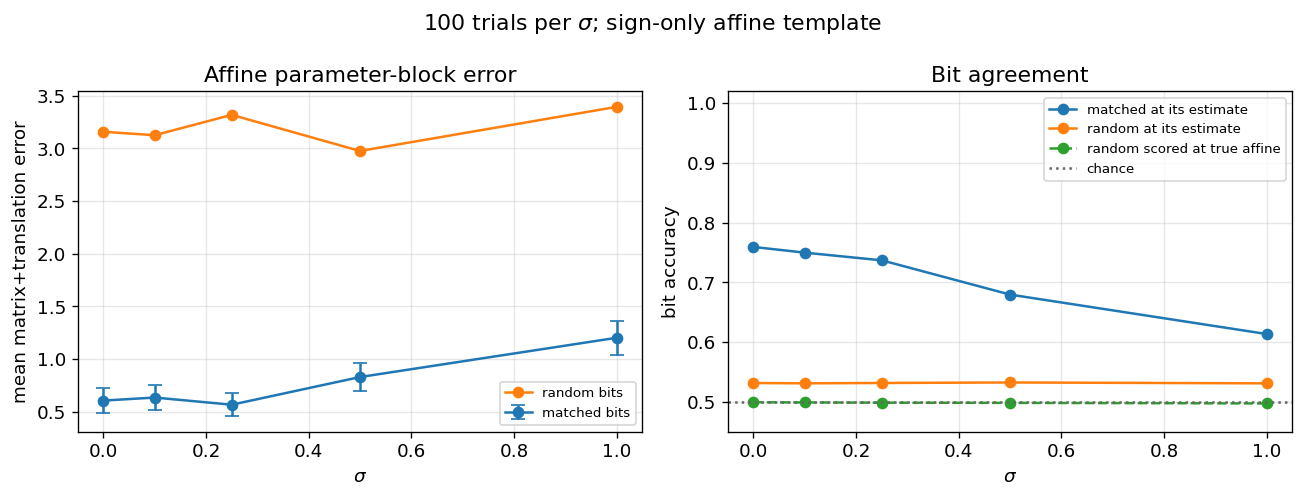

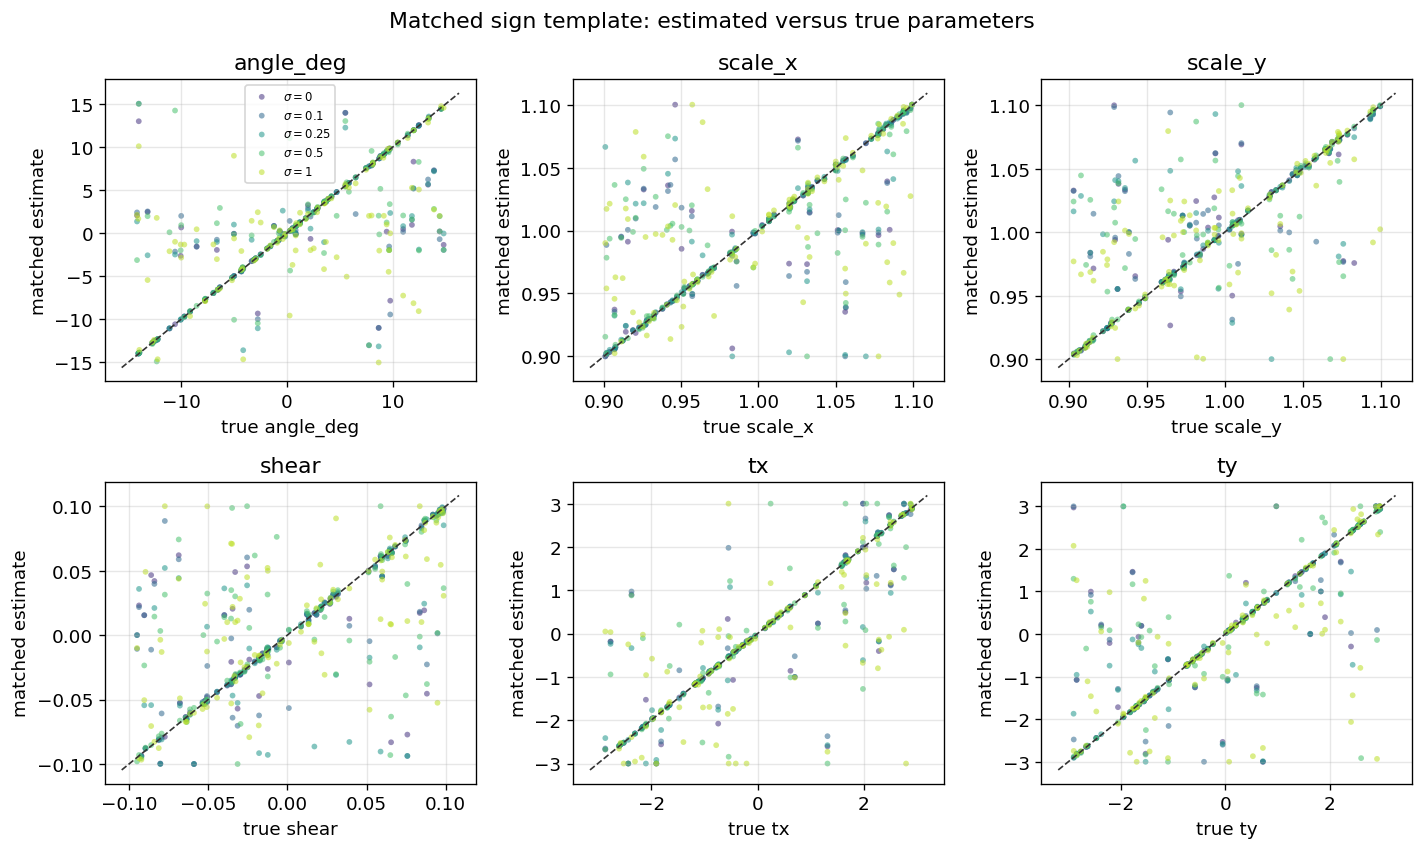

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
axes[0].errorbar(
    summary.noise_std,
    summary.matched_mean_matrix_error,
    yerr=summary.matched_std_matrix_error / np.sqrt(summary.n),
    fmt="-o",
    label="matched bits",
    capsize=4,
)
axes[0].plot(summary.noise_std, summary.random_mean_matrix_error, "-o", label="random bits")
axes[0].set_xlabel(r"$\sigma$")
axes[0].set_ylabel("mean matrix+translation error")
axes[0].set_title("Affine parameter-block error")
axes[0].legend(fontsize=8)

axes[1].plot(summary.noise_std, summary.matched_mean_bit_accuracy, "-o", label="matched at its estimate")
axes[1].plot(summary.noise_std, summary.random_mean_bit_accuracy, "-o", label="random at its estimate")
axes[1].plot(summary.noise_std, summary.random_bit_accuracy_at_true, "--o", label="random scored at true affine")
axes[1].axhline(0.5, color="0.4", ls=":", label="chance")
axes[1].set_xlabel(r"$\sigma$")
axes[1].set_ylabel("bit accuracy")
axes[1].set_ylim(0.45, 1.02)
axes[1].set_title("Bit agreement")
axes[1].legend(fontsize=8)
fig.suptitle(rf"{N_TRIALS} trials per $\sigma$; sign-only affine template")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "error_and_bits_vs_noise.png", bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(2, 3, figsize=(12, 7.2))
colors = plt.cm.viridis(np.linspace(0.15, 0.9, len(NOISE_LEVELS)))
for ax, name in zip(axes.ravel(), PARAM_NAMES):
    for noise_std, color in zip(NOISE_LEVELS, colors):
        block = results.loc[np.isclose(results.noise_std, noise_std)]
        ax.scatter(
            block[f"true_{name}"],
            block[f"matched_est_{name}"],
            s=12,
            alpha=0.55,
            color=color,
            edgecolors="none",
            label=rf"$\sigma={noise_std:g}$",
        )
    lo = float(results[f"true_{name}"].min())
    hi = float(results[f"true_{name}"].max())
    pad = 0.05 * (hi - lo + 1e-9)
    ax.plot([lo - pad, hi + pad], [lo - pad, hi + pad], color="0.2", ls="--", lw=1)
    ax.set_xlabel(f"true {name}")
    ax.set_ylabel("matched estimate")
    ax.set_title(name)
axes[0, 0].legend(fontsize=7, loc="best")
fig.suptitle("Matched sign template: estimated versus true parameters")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "matched_estimated_vs_true_params.png", bbox_inches="tight")
plt.show()


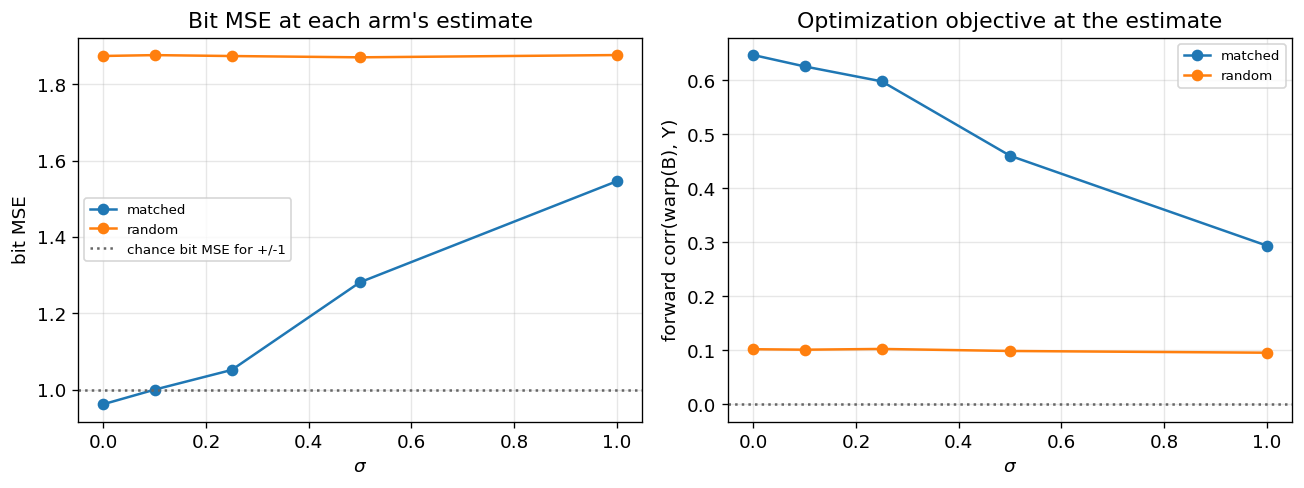

Fraction with matrix error <= 0.2:
           matched  random
noise_std                 
0.00          0.75     0.0
0.10          0.73     0.0
0.25          0.73     0.0
0.50          0.62     0.0
1.00          0.50     0.0


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
axes[0].plot(summary.noise_std, summary.matched_mean_bit_mse, "-o", label="matched")
axes[0].plot(summary.noise_std, summary.random_mean_bit_mse, "-o", label="random")
axes[0].axhline(1.0, color="0.4", ls=":", label="chance bit MSE for +/-1")
axes[0].set_xlabel(r"$\sigma$")
axes[0].set_ylabel("bit MSE")
axes[0].set_title("Bit MSE at each arm's estimate")
axes[0].legend(fontsize=8)

axes[1].plot(summary.noise_std, summary.matched_mean_forward_corr, "-o", label="matched")
axes[1].plot(summary.noise_std, summary.random_mean_forward_corr, "-o", label="random")
axes[1].axhline(0.0, color="0.4", ls=":")
axes[1].set_xlabel(r"$\sigma$")
axes[1].set_ylabel("forward corr(warp(B), Y)")
axes[1].set_title("Optimization objective at the estimate")
axes[1].legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "mse_and_correlation_vs_noise.png", bbox_inches="tight")
plt.show()

near = results.assign(
    matched_good=lambda frame: frame.matched_matrix_error <= 0.2,
    random_good=lambda frame: frame.random_matrix_error <= 0.2,
)
print("Fraction with matrix error <= 0.2:")
print(
    near.groupby("noise_std")[["matched_good", "random_good"]]
    .mean()
    .rename(columns={"matched_good": "matched", "random_good": "random"})
    .round(3)
)


## 6. Interpretation

If the matched arm recovers the affine and high bit accuracy while the random arm stays near chance, the sign template carries real geometric signal. If the random arm also looks successful after optimization, correspondences are being invented.


In [9]:
metadata = {
    "seed": SEED,
    "image_size": IMAGE_SIZE,
    "n_trials": N_TRIALS,
    "noise_levels": NOISE_LEVELS,
    "template_access": "sign-only 0/1 bits from original image",
    "observation_access": "full grayscale affine-warped image plus noise",
    "optimizer": "maximize corr(warp(B_pm), Y); coarse angle/translation + L-BFGS-B; DE if no gain over identity",
    "parameterization": "angle_deg, scale_x, scale_y, shear, tx, ty",
    "bounds": {
        "angle_deg": list(ANGLE_RANGE),
        "scale": list(SCALE_RANGE),
        "shear": list(SHEAR_RANGE),
        "translation_px": list(TRANSLATION_RANGE),
    },
    "random_control": "independent sign field registered to the same observation",
    "valid_pixels": int(VALID_MASK.sum()),
}
(OUTPUT_DIR / "metadata.json").write_text(json.dumps(metadata, indent=2) + "\n", encoding="utf-8")

print("Interpretation")
print(
    f"- Matched zero-noise: matrix err={zero.matched_mean_matrix_error:.4f}, "
    f"bit accuracy={zero.matched_mean_bit_accuracy:.4f}."
)
print(
    f"- Random zero-noise: bit accuracy at estimate={zero.random_mean_bit_accuracy:.4f}, "
    f"at true affine={zero.random_bit_accuracy_at_true:.4f}."
)
print(
    f"- At sigma={summary.noise_std.iloc[-1]:g}: matched bit accuracy="
    f"{summary.matched_mean_bit_accuracy.iloc[-1]:.3f}, random="
    f"{summary.random_mean_bit_accuracy.iloc[-1]:.3f}."
)
gap = summary.matched_mean_bit_accuracy - summary.random_mean_bit_accuracy
print(
    f"- Mean matched-minus-random bit-accuracy gap: {gap.mean():.3f} "
    f"(min {gap.min():.3f}, max {gap.max():.3f})."
)
print(f"- Wrote {OUTPUT_DIR / 'metadata.json'}")


Interpretation
- Matched zero-noise: matrix err=0.6068, bit accuracy=0.7594.
- Random zero-noise: bit accuracy at estimate=0.5315, at true affine=0.4992.
- At sigma=1: matched bit accuracy=0.614, random=0.531.
- Mean matched-minus-random bit-accuracy gap: 0.176 (min 0.083, max 0.228).
- Wrote results\affine_registration_sign_template\metadata.json
